In [28]:

import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

#BENUTZT DATEN VON 30.06



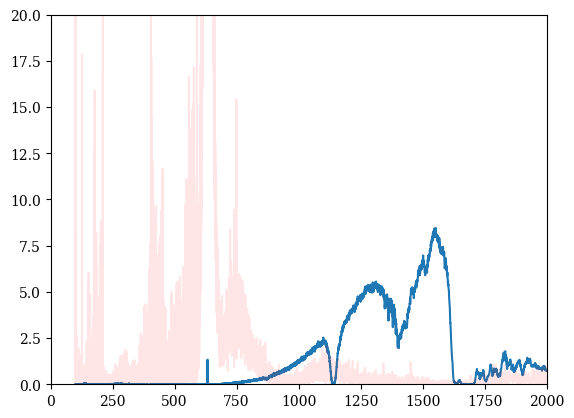

In [29]:

#gbenzol !!!! hat schmidl gesagt
weg01 = np.genfromtxt(
    'Spektrum_Glüh_20mm_benzol.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenlänge = weg01[:,0]
amplitude = weg01[:,1]

weg01_ref = np.genfromtxt(
    'Spektrum_Glüh_ref_benzol_20mm.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenlänge_ref = weg01_ref[:,0]
amplitude_ref = weg01_ref[:,1]

plt.plot(wellenlänge, amplitude)
plt.plot(wellenlänge_ref, amplitude_ref, alpha=0.1, color='red')
plt.xlim(0, 2000)
plt.ylim(0,20)
plt.show()

Hier jetzt Messungen vom 03.07

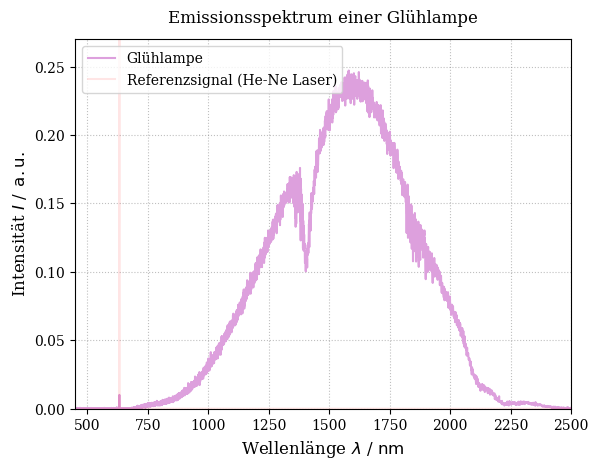

In [31]:
#glühlampe einfach so 

glüh = np.genfromtxt(
    'Spektrum-glüh.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenlänge_glüh = glüh[:,0]
wellenzahl_glüh=1e7/wellenlänge_glüh
amplitude_glüh = glüh[:,1]

glüh_ref = np.genfromtxt(
    'Spektrum-glüh_ref.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenlänge_glüh_ref = glüh_ref[:,0]
wellenzahl_glüh_ref=1e7/wellenlänge_glüh_ref
amplitude_glüh_ref = glüh_ref[:,1]

#------------------------------------------------------
#+ plank

plank_wellenlänge=np.linspace(1, 5000, 10000)

def plank(wellenlänge, temperatur):
    h = 6.62607015e-34  # Planck's constant in J*s
    c = 3e8  # Speed of light in m/s
    k = 1.380649e-23  # Boltzmann's constant in J/K
    wellenlänge_m = wellenlänge * 1e-9  # Convert nm to m
    return (2 * h * c**2) / (wellenlänge_m**5) * (1 / (np.exp((h * c) / (wellenlänge_m * k * temperatur)) - 1))

#------------------------------------------------------
plt.plot(wellenlänge_glüh, amplitude_glüh/np.max(amplitude_glüh), label='Glühlampe', color='plum')
plt.plot(wellenlänge_glüh_ref, amplitude_glüh_ref/np.max(amplitude_glüh_ref), alpha=0.1, color='red', label='Referenzsignal (He-Ne Laser)')
#plt.plot(plank_wellenlänge, plank(plank_wellenlänge, 2700)/np.max(plank(plank_wellenlänge, 3000)), label='Planksches Strahlungsgesetz (T=2700K)', color='blue')
plt.legend()
plt.title('Emissionsspektrum einer Glühlampe', pad=12)
plt.grid(True, which='both', linestyle=':', color='gray', alpha=0.5)
plt.xlabel(r'Wellenlänge $\lambda$ / $\mathrm{nm}$')
plt.ylabel(r'Intensität $I$ / $\,\mathrm{a.u.}$')

plt.xlim(450, 2500)
plt.ylim(0, 0.27)
plt.savefig('Emissionsspektrum_Gluehlampe.pdf', bbox_inches='tight') # Vektorgrafik für LaTeX-Dokumente
plt.show()



/var/folders/6b/y5ttkb6d5cz45vb2p8jqy0l40000gq/T/ipykernel_1567/1509673236.py:41: RuntimeWarning: overflow encountered in exp
  return (2 * h * c**2) / (wellenlänge_m**5) * (1 / (np.exp((h * c) / (wellenlänge_m * k * temperatur)) - 1))


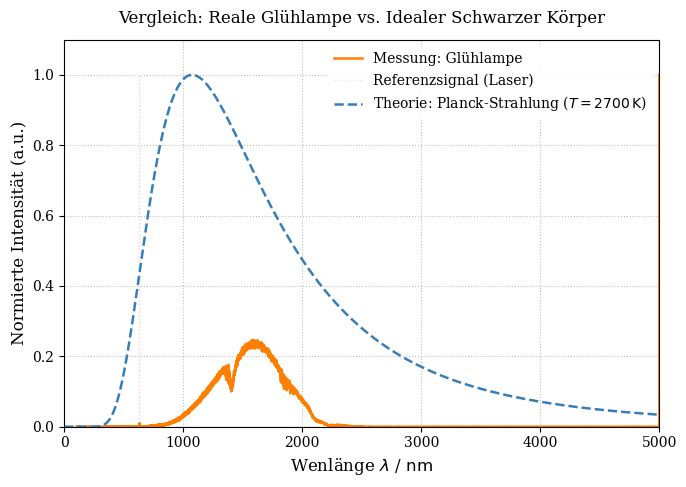

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# —————————————————————————————————————————————————————————————————————————————
# 1. DATEN LADEN & VERARBEITEN
# —————————————————————————————————————————————————————————————————————————————
# Hauptmessung Glühlampe laden
glüh = np.genfromtxt(
    'Spektrum-glüh.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)
wellenlänge_glüh = glüh[:, 0]
amplitude_glüh = glüh[:, 1]

# Referenzsignal (z.B. Laser / Detektor-Background) laden
glüh_ref = np.genfromtxt(
    'Spektrum-glüh_ref.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)
wellenlänge_glüh_ref = glüh_ref[:, 0]
amplitude_glüh_ref = glüh_ref[:, 1]

# —————————————————————————————————————————————————————————————————————————————
# 2. PLANCK-FUNKTION GENERIEREN
# —————————————————————————————————————————————————————————————————————————————
plank_wellenlänge = np.linspace(1, 5000, 10000)

def plank(wellenlänge, temperatur):
    h = 6.62607015e-34    # J*s
    c = 3e8               # m/s
    k = 1.380649e-23      # J/K
    wellenlänge_m = wellenlänge * 1e-9  # nm in m
    return (2 * h * c**2) / (wellenlänge_m**5) * (1 / (np.exp((h * c) / (wellenlänge_m * k * temperatur)) - 1))

# Berechne die theoretische Kurve für T = 2700 K
y_planck_2700 = plank(plank_wellenlänge, 2700)

# —————————————————————————————————————————————————————————————————————————————
# 3. HIGH-QUALITY PLOT-STYLING
# —————————————————————————————————————————————————————————————————————————————
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14
})

fig, ax = plt.subplots(figsize=(7, 5))
#fig, ax = plt.subplots(figsize=(7, 5), dpi=300)

# Plots einzeichnen (jeweils strikt auf das eigene Maximum normiert)
ax.plot(wellenlänge_glüh, amplitude_glüh / np.max(amplitude_glüh), 
        color='#ff7f00', lw=1.8, label='Messung: Glühlampe')

ax.plot(wellenlänge_glüh_ref, amplitude_glüh_ref / np.max(amplitude_glüh_ref), 
        color='#e41a1c', alpha=0.15, lw=1.0, ls=':', label='Referenzsignal (Laser)')

ax.plot(plank_wellenlänge, y_planck_2700 / np.max(y_planck_2700), 
        color='#377eb8', lw=1.8, ls='--', label='Theorie: Planck-Strahlung ($T=2700\,\mathrm{K}$)')

# —————————————————————————————————————————————————————————————————————————————
# 4. ACHSEN-MODIFIKATIONEN & EXPORT
# —————————————————————————————————————————————————————————————————————————————
ax.set_xlabel(r'Wenlänge $\lambda$ / $\mathrm{nm}$')
ax.set_ylabel(r'Normierte Intensität (a.u.)')
ax.set_title('Vergleich: Reale Glühlampe vs. Idealer Schwarzer Körper', pad=12)

# Grenzen setzen
ax.set_xlim(0, 5000)
ax.set_ylim(0, 1.1)  # Etwas Platz nach oben für die Legende

# Professionelle Details
ax.grid(True, which='both', linestyle=':', color='gray', alpha=0.5)
ax.legend(loc='upper right', frameon=True, framealpha=0.9, edgecolor='none')

# Exportieren für LaTeX (PDF) und Präsentationen (PNG)
plt.tight_layout()
#fig.savefig('Vergleich_Planck_Gluehlampe.pdf', bbox_inches='tight')
#fig.savefig('Vergleich_Planck_Gluehlampe.png', bbox_inches='tight', dpi=300)

plt.show()

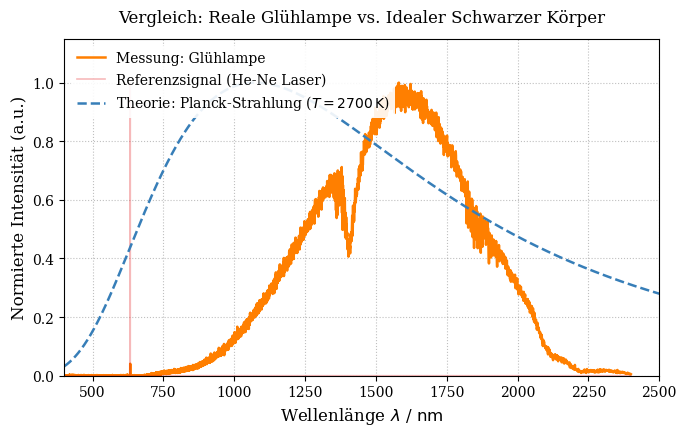

In [33]:
import numpy as np
import matplotlib.pyplot as plt

# —————————————————————————————————————————————————————————————————————————————
# 1. DATEN LADEN & VERARBEITEN
# —————————————————————————————————————————————————————————————————————————————
# Hauptmessung Glühlampe laden
glüh = np.genfromtxt(
    'Spektrum-glüh.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)
wellenlänge_glüh = glüh[:, 0]
amplitude_glüh = glüh[:, 1]

# AUSREISSER ENTFERNEN: Schneide Daten ab einer Wellenlänge von 2400 nm ab
gute_indizes = wellenlänge_glüh < 2400.0
wellenlänge_glüh = wellenlänge_glüh[gute_indizes]
amplitude_glüh = amplitude_glüh[gute_indizes]

# Referenzsignal (z.B. Laser / Detektor-Background) laden
glüh_ref = np.genfromtxt(
    'Spektrum-glüh_ref.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)
wellenlänge_glüh_ref = glüh_ref[:, 0]
amplitude_glüh_ref = glüh_ref[:, 1]

# Auch beim Referenzsignal den Ausreißer-Bereich abschneiden
gute_indizes_ref = wellenlänge_glüh_ref < 2400.0
wellenlänge_glüh_ref = wellenlänge_glüh_ref[gute_indizes_ref]
amplitude_glüh_ref = amplitude_glüh_ref[gute_indizes_ref]

# —————————————————————————————————————————————————————————————————————————————
# 2. PLANCK-FUNKTION GENERIEREN
# —————————————————————————————————————————————————————————————————————————————
# Definiere den Bereich passend zum sinnvollen Messbereich des Detektors
plank_wellenlänge = np.linspace(350, 2500, 10000)

def plank(wellenlänge, temperatur):
    h = 6.62607015e-34    # J*s
    c = 3e8               # m/s
    k = 1.380649e-23      # J/K
    wellenlänge_m = wellenlänge * 1e-9  # nm in m
    return (2 * h * c**2) / (wellenlänge_m**5) * (1 / (np.exp((h * c) / (wellenlänge_m * k * temperatur)) - 1))

# Berechne die theoretische Kurve für T = 2700 K
y_planck_2700 = plank(plank_wellenlänge, 2700)

# —————————————————————————————————————————————————————————————————————————————
# 3. HIGH-QUALITY PLOT-STYLING
# —————————————————————————————————————————————————————————————————————————————
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14
})

fig, ax = plt.subplots(figsize=(7, 4.5))

# Plots einzeichnen (Jetzt korrekt auf die bereinigten Maxima normiert)
ax.plot(wellenlänge_glüh, amplitude_glüh / np.max(amplitude_glüh), 
        color='#ff7f00', lw=1.8, label='Messung: Glühlampe')

ax.plot(wellenlänge_glüh_ref, amplitude_glüh_ref / np.max(amplitude_glüh_ref), 
        color='#e41a1c', alpha=0.3, lw=1.2, label='Referenzsignal (He-Ne Laser)')

ax.plot(plank_wellenlänge, y_planck_2700 / np.max(y_planck_2700), 
        color='#377eb8', lw=1.8, ls='--', label='Theorie: Planck-Strahlung ($T=2700\,\mathrm{K}$)')

# —————————————————————————————————————————————————————————————————————————————
# 4. ACHSEN-MODIFIKATIONEN & EXPORT
# —————————————————————————————————————————————————————————————————————————————
ax.set_xlabel(r'Wellenlänge $\lambda$ / $\mathrm{nm}$')  # Tippfehler korrigiert
ax.set_ylabel(r'Normierte Intensität (a.u.)')
ax.set_title('Vergleich: Reale Glühlampe vs. Idealer Schwarzer Körper', pad=12)

# Grenzen sinnvoll anpassen (Fokus auf den VIS/NIR-Bereich des Detektors)
ax.set_xlim(400, 2500)
ax.set_ylim(0, 1.15)  # Etwas Platz nach oben für die Legende

# Professionelle Details
ax.grid(True, which='both', linestyle=':', color='gray', alpha=0.5)
ax.legend(loc='upper left', frameon=True, framealpha=0.9, edgecolor='none')

plt.tight_layout()

# Exportieren für Beamer/LaTeX
#
fig.savefig('Vergleich_Planck_Gluehlampe.pdf', bbox_inches='tight')
# fig.savefig('Vergleich_Planck_Gluehlampe.png', bbox_inches='tight', dpi=300)

plt.show()

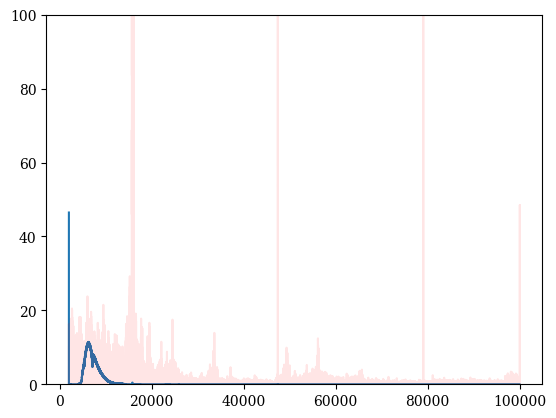

In [34]:
#glüh ohne benzol  mot wellenzahl
glüh = np.genfromtxt(
    'Spektrum-glüh.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenlänge_glüh = glüh[:,0]
wellenzahl_glüh=1e7/wellenlänge_glüh
amplitude_glüh = glüh[:,1]

glüh_ref = np.genfromtxt(
    'Spektrum-glüh_ref.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenlänge_glüh_ref = glüh_ref[:,0]
wellenzahl_glüh_ref=1e7/wellenlänge_glüh_ref
amplitude_glüh_ref = glüh_ref[:,1]

plt.plot(wellenzahl_glüh, amplitude_glüh)
plt.plot(wellenzahl_glüh_ref, amplitude_glüh_ref, alpha=0.1, color='red')

plt.ylim(0, 100)
plt.show()

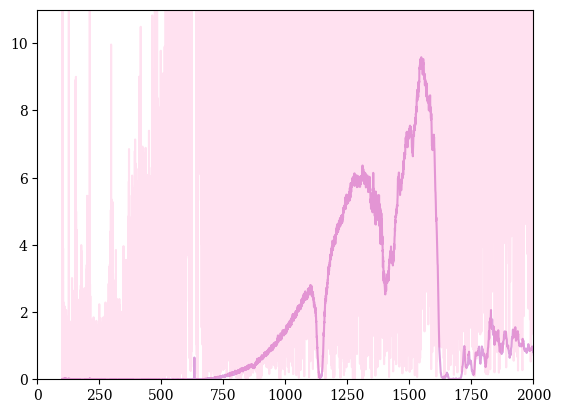

In [35]:
#glüh mit benzol 
benzol = np.genfromtxt(
    'Spektrum-glüh_benzol.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenlänge_benzol = benzol[:,0]
wellenzahl_benzol=1e7/wellenlänge_benzol

amplitude_benzol = benzol[:,1]

benzol_ref = np.genfromtxt(
    'Spektrum-glüh_benzol_ref.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenlänge_benzol_ref = benzol_ref[:,0]
wellenzahl_benzol_ref=1e7/wellenlänge_benzol_ref
amplitude_benzol_ref = benzol_ref[:,1]

plt.plot(wellenlänge_benzol, amplitude_benzol, color='plum')
plt.plot(wellenlänge_benzol_ref, amplitude_benzol_ref, alpha=0.2, color='hotpink')
plt.xlim(0, 2000)
plt.ylim(0,11)
plt.show()
plt.show()

/var/folders/6b/y5ttkb6d5cz45vb2p8jqy0l40000gq/T/ipykernel_1567/1350640406.py:2: RuntimeWarning: divide by zero encountered in divide
  benzol_ohne_hintergrund =   amplitude_glüh/amplitude_benzol
/var/folders/6b/y5ttkb6d5cz45vb2p8jqy0l40000gq/T/ipykernel_1567/1350640406.py:2: RuntimeWarning: invalid value encountered in divide
  benzol_ohne_hintergrund =   amplitude_glüh/amplitude_benzol
/var/folders/6b/y5ttkb6d5cz45vb2p8jqy0l40000gq/T/ipykernel_1567/1350640406.py:3: RuntimeWarning: divide by zero encountered in divide
  benzol_ohne_hintergrund_t =   amplitude_benzol/amplitude_glüh
/var/folders/6b/y5ttkb6d5cz45vb2p8jqy0l40000gq/T/ipykernel_1567/1350640406.py:3: RuntimeWarning: invalid value encountered in divide
  benzol_ohne_hintergrund_t =   amplitude_benzol/amplitude_glüh


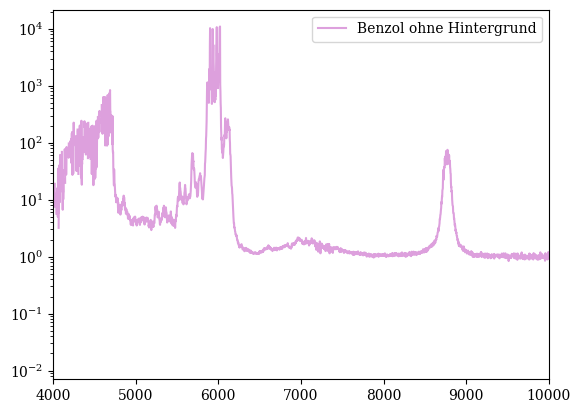

In [36]:

# benzol/ glüh = tran smissionspektrum benzol
benzol_ohne_hintergrund =   amplitude_glüh/amplitude_benzol
benzol_ohne_hintergrund_t =   amplitude_benzol/amplitude_glüh

#plt.plot(wellenlänge_glüh, amplitude_glüh, label='Glüh ohne Benzol', color='orange')
#plt.plot(wellenlänge_benzol, amplitude_benzol, label='Glüh mit Benzol', color='blue')
#plt.plot(wellenlänge_benzol, benzol_ohne_hintergrund, label='Benzol ohne Hintergrund', color='hotpink')
plt.xlim(4000, 10000)
plt.semilogy(wellenzahl_benzol, benzol_ohne_hintergrund, label='Benzol ohne Hintergrund', color='plum')
plt.legend()
#plt.ylim(0,20)
plt.show()
plt.show()
#vegrelichsbild benzol transmission zeigen

/var/folders/6b/y5ttkb6d5cz45vb2p8jqy0l40000gq/T/ipykernel_1567/1410643987.py:1: RuntimeWarning: divide by zero encountered in divide
  benzol_ohne_hintergrund =   amplitude_glüh/amplitude_benzol
/var/folders/6b/y5ttkb6d5cz45vb2p8jqy0l40000gq/T/ipykernel_1567/1410643987.py:1: RuntimeWarning: invalid value encountered in divide
  benzol_ohne_hintergrund =   amplitude_glüh/amplitude_benzol
/var/folders/6b/y5ttkb6d5cz45vb2p8jqy0l40000gq/T/ipykernel_1567/1410643987.py:2: RuntimeWarning: divide by zero encountered in divide
  benzol_ohne_hintergrund_anders =   amplitude_benzol/amplitude_glüh
/var/folders/6b/y5ttkb6d5cz45vb2p8jqy0l40000gq/T/ipykernel_1567/1410643987.py:2: RuntimeWarning: invalid value encountered in divide
  benzol_ohne_hintergrund_anders =   amplitude_benzol/amplitude_glüh


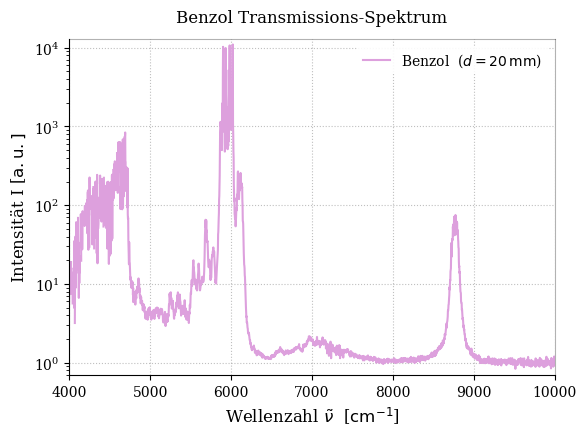

In [37]:


benzol_ohne_hintergrund =   amplitude_glüh/amplitude_benzol
benzol_ohne_hintergrund_anders =   amplitude_benzol/amplitude_glüh

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14
})

# Erstellung der Figur im typischen einspaltigen Paper-Format (ca. 8.5 cm Breite)
fig, ax = plt.subplots(figsize=(6, 4.5))
#fig, ax = plt.subplots(figsize=(6, 4.5), dpi=300)

# Plots zeichnen
# Referenz zuerst, damit die Hauptmessung physisch darüber liegt
'''ax.semilogy(wellenzahl_benzol_ref, amplitude_benzol_ref, 
        color='#e41a1c', alpha=0.3, lw=1.2, ls='--', 
        label='Referenzspektrum')'''

ax.semilogy(wellenzahl_benzol, benzol_ohne_hintergrund, 
        color='plum', lw=1.5, 
        label='Benzol  ($d = 20\,\mathrm{mm}$)')

# —————————————————————————————————————————————————————————————————————————————
# 3. ACHSEN, TITEL & LEGENDE
# —————————————————————————————————————————————————————————————————————————————
# Präzise Achsenbeschriftung mit korrekten physikalischen Einheiten in LaTeX
ax.set_xlabel(r'Wellenzahl $\tilde{\nu}$  [$\mathrm{cm}^{-1}$]')
ax.set_ylabel(r'Intensität I [$\mathrm{a.u.}]$')
ax.set_title('Benzol Transmissions-Spektrum', pad=12)

# Grenzen exakt wie vorgegeben (angepasst an die Skalierung / 1000)
ax.set_xlim(4000, 10000)
ax.set_ylim(0.7, 13000)

# Dezentes, professionelles Grid
ax.grid(True, linestyle=':', color='gray', alpha=0.5)
#ax.grid(True, linestyle=':', which='both', color='gray', alpha=0.5)

# Rahmen (Spines) oben und rechts sichtbar lassen, aber dezent (Standard im Physik-Paper)
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['top'].set_alpha(0.3)
ax.spines['right'].set_alpha(0.3)

# Legende ohne störenden dicken Rahmen, leicht transparent platziert
ax.legend(loc='upper right', frameon=True, framealpha=0.9, edgecolor='none')

# Layout optimieren und speichern
plt.tight_layout()
fig.savefig('Benzol Transmissionsspektrum.pdf', bbox_inches='tight') # Vektorgrafik für LaTeX-Dokumente
#fig.savefig('Benzol_Transmission_Publication.png', bbox_inches='tight', dpi=300)

/var/folders/6b/y5ttkb6d5cz45vb2p8jqy0l40000gq/T/ipykernel_1567/367282392.py:1: RuntimeWarning: divide by zero encountered in divide
  benzol_ohne_hintergrund =   amplitude_glüh/amplitude_benzol
/var/folders/6b/y5ttkb6d5cz45vb2p8jqy0l40000gq/T/ipykernel_1567/367282392.py:1: RuntimeWarning: invalid value encountered in divide
  benzol_ohne_hintergrund =   amplitude_glüh/amplitude_benzol
/var/folders/6b/y5ttkb6d5cz45vb2p8jqy0l40000gq/T/ipykernel_1567/367282392.py:2: RuntimeWarning: divide by zero encountered in divide
  benzol_ohne_hintergrund_anders =   amplitude_benzol/amplitude_glüh
/var/folders/6b/y5ttkb6d5cz45vb2p8jqy0l40000gq/T/ipykernel_1567/367282392.py:2: RuntimeWarning: invalid value encountered in divide
  benzol_ohne_hintergrund_anders =   amplitude_benzol/amplitude_glüh


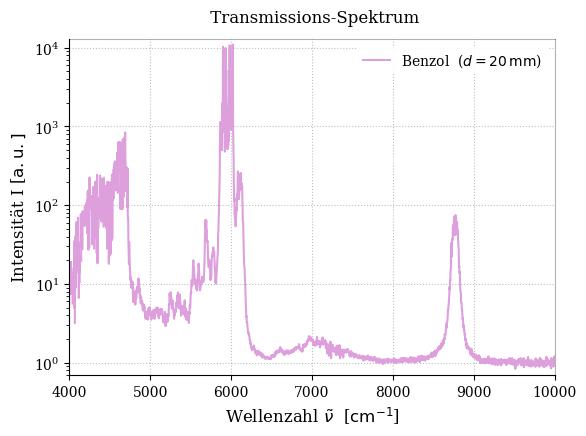

In [38]:


benzol_ohne_hintergrund =   amplitude_glüh/amplitude_benzol
benzol_ohne_hintergrund_anders =   amplitude_benzol/amplitude_glüh

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14
})

# Erstellung der Figur im typischen einspaltigen Paper-Format (ca. 8.5 cm Breite)
fig, ax = plt.subplots(figsize=(6, 4.5))
#fig, ax = plt.subplots(figsize=(6, 4.5), dpi=300)

# Plots zeichnen
# Referenz zuerst, damit die Hauptmessung physisch darüber liegt
'''ax.semilogy(wellenzahl_benzol_ref, amplitude_benzol_ref, 
        color='#e41a1c', alpha=0.3, lw=1.2, ls='--', 
        label='Referenzspektrum')'''

ax.semilogy(wellenzahl_benzol, benzol_ohne_hintergrund, 
        color='plum', lw=1.5, 
        label='Benzol  ($d = 20\,\mathrm{mm}$)')

# —————————————————————————————————————————————————————————————————————————————
# 3. ACHSEN, TITEL & LEGENDE
# —————————————————————————————————————————————————————————————————————————————
# Präzise Achsenbeschriftung mit korrekten physikalischen Einheiten in LaTeX
ax.set_xlabel(r'Wellenzahl $\tilde{\nu}$  [$\mathrm{cm}^{-1}$]')
ax.set_ylabel(r'Intensität I [$\mathrm{a.u.}]$')
#ax.set_title('Benzol Transmissions-Spektrum', pad=12)
ax.set_title(' Transmissions-Spektrum', pad=12)

# Grenzen exakt wie vorgegeben (angepasst an die Skalierung / 1000)
ax.set_xlim(4000, 10000)
ax.set_ylim(0.7, 13000)

# Dezentes, professionelles Grid
ax.grid(True, linestyle=':', color='gray', alpha=0.5)
#ax.grid(True, linestyle=':', which='both', color='gray', alpha=0.5)

# Rahmen (Spines) oben und rechts sichtbar lassen, aber dezent (Standard im Physik-Paper)
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['top'].set_alpha(0.3)
ax.spines['right'].set_alpha(0.3)

# Legende ohne störenden dicken Rahmen, leicht transparent platziert
ax.legend(loc='upper right', frameon=True, framealpha=0.9, edgecolor='none')

# Layout optimieren und speichern
plt.tight_layout()
#fig.savefig('Benzol_Transmission_d20mm.pdf', bbox_inches='tight') # Vektorgrafik für LaTeX-Dokumente

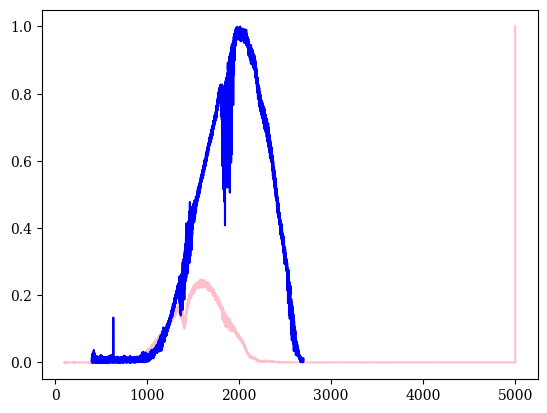

In [39]:
#vergkeich ir ft und alte maschine

df = pd.read_csv("ft_ir_none.csv", comment="#")
wellenlänge_neu = df["Wavelength"].values
wellenzahl_neu = df["Wavenumber"].values
amplitude_neu = df["CH1 FFT"].values
amplitude_ref_neu = df["Reference FFT"].values

#mask = amplitude_glüh < 1.0

#wellenlänge_glüh = wellenlänge_glüh[mask]

plt.plot(wellenlänge_glüh, amplitude_glüh/np.max(amplitude_glüh), label='altes ding nur luft', color='pink')
plt.plot(wellenlänge_neu, amplitude_neu/np.max(amplitude_neu), label='neues ding nur luft', color='blue')

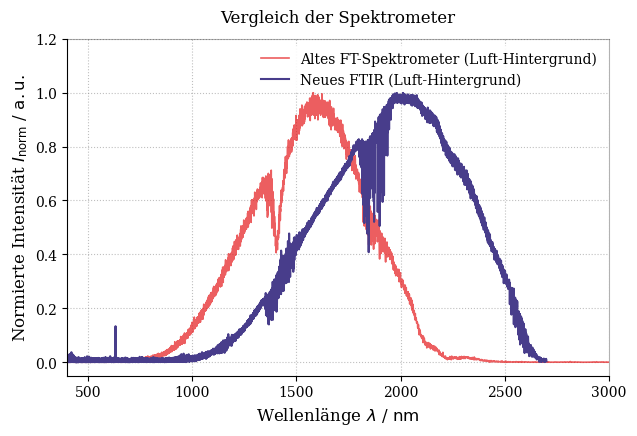

In [40]:
ausreisser_maske = (wellenlänge_glüh < 4900) | (wellenlänge_glüh > 5100)

wellenlänge_glüh_clean = wellenlänge_glüh[ausreisser_maske]
amplitude_glüh_clean = amplitude_glüh[ausreisser_maske]

# —————————————————————————————————————————————————————————————————————————————
# 3. NORMIERUNG AUF DAS MAXIMUM (0 bis 1)
# —————————————————————————————————————————————————————————————————————————————
# Jetzt greift die Normierung fehlerfrei auf den echten physikalischen Peak!
amp_glüh_norm = amplitude_glüh_clean / np.max(amplitude_glüh_clean)
amp_neu_norm = amplitude_neu / np.max(amplitude_neu)

# —————————————————————————————————————————————————————————————————————————————
# 4. PROFESSIONELLES GRAPH-STYLING
# —————————————————————————————————————————————————————————————————————————————
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10
})

fig, ax = plt.subplots(figsize=(6.5, 4.5))

# Plots zeichnen
ax.plot(wellenlänge_glüh_clean, amp_glüh_norm, 
        color='#e41a1c', alpha=0.7, lw=1.2, 
        label='Altes FT-Spektrometer (Luft-Hintergrund)')

ax.plot(wellenlänge_neu, amp_neu_norm, 
        color='darkslateblue', lw=1.5, 
        label='Neues FTIR (Luft-Hintergrund)')

# Achsenbeschriftungen (Passe die Einheit an, falls du Wellenzahl cm^-1 plottest!)
ax.set_xlabel(r'Wellenlänge $\lambda$ / $\mathrm{nm}$')
ax.set_ylabel(r'Normierte Intensität $I_{\mathrm{norm}}$ / $\mathrm{a.u.}$')
ax.set_title('Vergleich der Spektrometer', pad=12)

# Sinnvolle Grenzen setzen (Passe x_min und x_max an deinen Messbereich an)
ax.set_ylim(-0.05, 1.2) 
ax.set_xlim(400, 3000) 
ax.grid(True, which='both', linestyle=':', color='gray', alpha=0.5)

# Diskreter wissenschaftlicher Rahmen
ax.spines['top'].set_alpha(0.3)
ax.spines['right'].set_alpha(0.3)

ax.legend(loc='upper right', frameon=True, framealpha=0.9, edgecolor='none')

plt.tight_layout()
plt.show()
#fig.savefig('Vergleich_Spektrometer.pdf', bbox_inches='tight') # Vektorgrafik für LaTeX-Dokumente